# Quantifying Uncertainty in Small-Sample Comparisons: A Simulation Study Motivated by FSIP2-Associated Male Infertility

## 1. Background and research question

Research on FSIP2-associated male infertility motivates the broader problem of drawing reliable conclusions from small biological studies. This project uses statistical simulation to investigate how sample size, measurement variability, and true effect size influence estimation uncertainty and statistical power.

**Research question:** How do sample size, measurement variability, and true effect size influence the accuracy, uncertainty, and statistical power of a two-group comparison motivated by research on FSIP2-associated male infertility?

## 2. Study design

This is a computational simulation study involving two hypothetical independent groups and a continuous outcome. All observations will be generated computationally and will not represent actual patients or experimental measurements.

## 3. Statistical approach

The analysis will examine the sampling distribution of the difference in group means, estimate uncertainty using bootstrap confidence intervals, and evaluate differences using Welch's two-sample t-test. Statistical power will be investigated by varying sample size, outcome variability, and the true effect size.

An assumption-violating counterexample will examine how unequal variances combined with unequal sample sizes may affect statistical inference.

## 4. Reproducibility and limitations

Random seeds, software dependencies, simulation settings, and generated results will be documented. Findings will be interpreted as evidence about statistical methods under specified simulation conditions, not as biological evidence about FSIP2 mutations or clinical outcomes.

In [13]:
# DS-A2: Inference and Uncertainty Notebook

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats

# Reproducibility
SEED = 20261009
rng = np.random.default_rng(SEED)

# Statistical settings
ALPHA = 0.05
CONFIDENCE_LEVEL = 0.95
MIN_MEANINGFUL_EFFECT = 0.5  # Standardized effect size

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("SciPy version:", scipy.__version__)
print("Random seed:", SEED)
print("Significance level:", ALPHA)
print("Confidence level:", CONFIDENCE_LEVEL)
print("Minimum meaningful standardized effect:",
      MIN_MEANINGFUL_EFFECT)

Python version: 3.13.16
NumPy version: 2.1.3
Pandas version: 2.2.3
SciPy version: 1.16.3
Random seed: 20261009
Significance level: 0.05
Confidence level: 0.95
Minimum meaningful standardized effect: 0.5


### 5. Sampling distribution of the difference in means

A sampling distribution describes how a statistic varies across repeated samples drawn under the same population model.

In this study, the statistic is the difference between the sample means of two independent groups. We will simulate repeated experiments under a normal population model with equal standard deviations.

The control population has a mean of 0 standardized units, while the treatment population has a mean of 0.5 standardized units. Both populations have a standard deviation of 1, and each group contains 20 observations per experiment.

We will repeat the experiment 5,000 times and compare the simulated sampling distribution with its theoretical mean and standard error. These are synthetic observations, not actual patient data.

Number of simulated experiments: 5000
Sample size per group: 20
True population mean difference: 0.5
Theoretical standard error: 0.3162
Simulated mean difference: 0.4992
Simulated standard deviation: 0.3135
Simulated bias: -0.0008


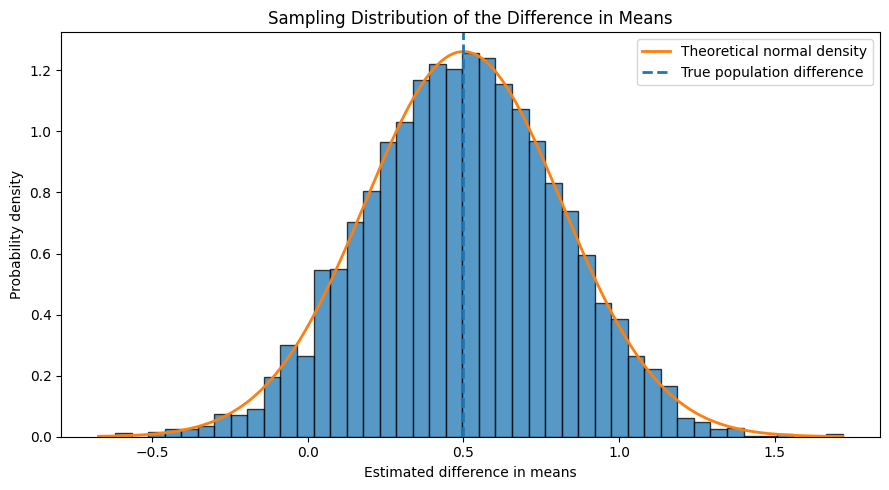

In [14]:
# Step 6: Sampling distribution simulation

# Predefined simulation settings
N_PER_GROUP = 20
N_SIMULATIONS = 5000

CONTROL_MEAN = 0.0
TRUE_EFFECT = 0.5
TREATMENT_MEAN = CONTROL_MEAN + TRUE_EFFECT
POPULATION_SD = 1.0

# Use a dedicated random generator for this simulation
sampling_rng = np.random.default_rng(SEED)

# Store the estimated difference from every simulated experiment
mean_differences = np.empty(N_SIMULATIONS)

for i in range(N_SIMULATIONS):
    control = sampling_rng.normal(
        loc=CONTROL_MEAN,
        scale=POPULATION_SD,
        size=N_PER_GROUP
    )

    treatment = sampling_rng.normal(
        loc=TREATMENT_MEAN,
        scale=POPULATION_SD,
        size=N_PER_GROUP
    )

    mean_differences[i] = treatment.mean() - control.mean()

# Theoretical and simulated summaries
theoretical_se = POPULATION_SD * np.sqrt(2 / N_PER_GROUP)

print("Number of simulated experiments:", N_SIMULATIONS)
print("Sample size per group:", N_PER_GROUP)
print("True population mean difference:", TRUE_EFFECT)
print("Theoretical standard error:", round(theoretical_se, 4))
print("Simulated mean difference:", round(mean_differences.mean(), 4))
print("Simulated standard deviation:", round(mean_differences.std(ddof=1), 4))
print("Simulated bias:", round(mean_differences.mean() - TRUE_EFFECT, 4))

# Plot the sampling distribution
plt.figure(figsize=(9, 5))

plt.hist(
    mean_differences,
    bins=45,
    density=True,
    alpha=0.75,
    edgecolor="black"
)

# Theoretical normal density
x = np.linspace(
    mean_differences.min(),
    mean_differences.max(),
    400
)

theoretical_density = stats.norm.pdf(
    x,
    loc=TRUE_EFFECT,
    scale=theoretical_se
)

plt.plot(
    x,
    theoretical_density,
    linewidth=2,
    label="Theoretical normal density"
)

plt.axvline(
    TRUE_EFFECT,
    linestyle="--",
    linewidth=2,
    label="True population difference"
)

plt.xlabel("Estimated difference in means")
plt.ylabel("Probability density")
plt.title("Sampling Distribution of the Difference in Means")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Bootstrap confidence interval and hypothesis test

A point estimate alone does not show how uncertain an estimate is. This section uses one simulated experiment to estimate the difference between two population means.

The bootstrap estimates uncertainty by repeatedly resampling observations with replacement within each group and recalculating the difference in sample means. The 2.5th and 97.5th percentiles of the bootstrap distribution form a percentile-based 95% confidence interval.

Welch's two-sample t-test evaluates the null hypothesis that the population means are equal without assuming equal population variances. We will also calculate a 95% Welch confidence interval for comparison.

The bootstrap interval and the Welch interval use different methods and need not be identical. Their performance depends on the data and assumptions; neither interval is guaranteed to contain the true effect in every experiment.

Control sample mean: 0.021
Treatment sample mean: 0.421
Observed difference in means: 0.4

Bootstrap 95% confidence interval:
(np.float64(-0.319), np.float64(1.1359))

Welch 95% confidence interval:
(np.float64(-0.3943), np.float64(1.1944))

Welch t-statistic: 1.0252
Welch degrees of freedom: 32.4192
Welch p-value: 0.3128
Decision: Do not reject the null hypothesis at alpha = 0.05.


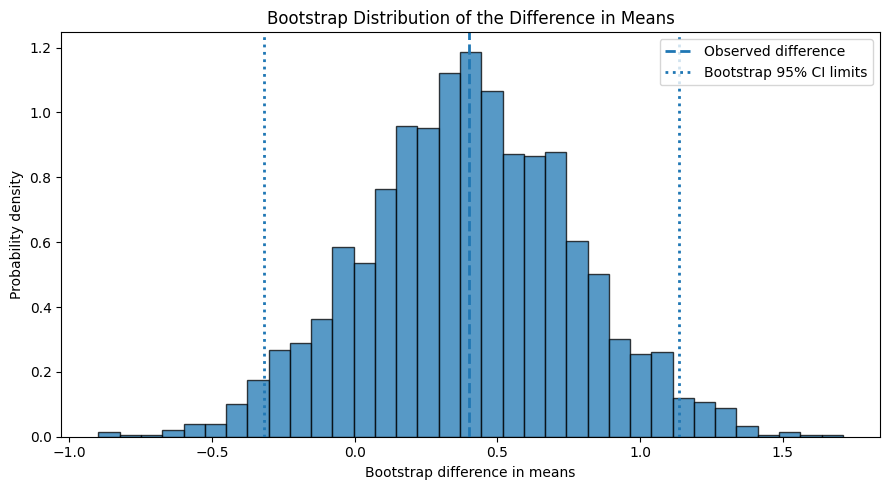

In [15]:
# Step 7: Bootstrap confidence interval and Welch's t-test

# Generate one new, reproducible hypothetical experiment
N_BOOTSTRAP = 2000
N_PER_GROUP = 20

experiment_rng = np.random.default_rng(SEED + 1)

control_sample = experiment_rng.normal(
    loc=0.0,
    scale=1.0,
    size=N_PER_GROUP
)

treatment_sample = experiment_rng.normal(
    loc=0.5,
    scale=1.0,
    size=N_PER_GROUP
)

# Observed difference in sample means
observed_difference = (
    treatment_sample.mean() - control_sample.mean()
)

# Bootstrap: resample each group independently
bootstrap_rng = np.random.default_rng(SEED + 2)

bootstrap_differences = np.empty(N_BOOTSTRAP)

for b in range(N_BOOTSTRAP):
    boot_control = bootstrap_rng.choice(
        control_sample,
        size=N_PER_GROUP,
        replace=True
    )

    boot_treatment = bootstrap_rng.choice(
        treatment_sample,
        size=N_PER_GROUP,
        replace=True
    )

    bootstrap_differences[b] = (
        boot_treatment.mean() - boot_control.mean()
    )

# Percentile-based bootstrap 95% confidence interval
bootstrap_ci = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

# Welch's two-sample t-test
welch_result = stats.ttest_ind(
    treatment_sample,
    control_sample,
    equal_var=False,
    alternative="two-sided"
)

# Welch 95% confidence interval
n_t = len(treatment_sample)
n_c = len(control_sample)

var_t = np.var(treatment_sample, ddof=1)
var_c = np.var(control_sample, ddof=1)

se_welch = np.sqrt(var_t / n_t + var_c / n_c)

df_welch = (
    (var_t / n_t + var_c / n_c) ** 2
    / (
        (var_t / n_t) ** 2 / (n_t - 1)
        + (var_c / n_c) ** 2 / (n_c - 1)
    )
)

critical_t = stats.t.ppf(
    0.975,
    df=df_welch
)

welch_ci = (
    observed_difference - critical_t * se_welch,
    observed_difference + critical_t * se_welch
)

# Report results
print("Control sample mean:",
      round(control_sample.mean(), 4))

print("Treatment sample mean:",
      round(treatment_sample.mean(), 4))

print("Observed difference in means:",
      round(observed_difference, 4))

print("\nBootstrap 95% confidence interval:")
print(tuple(np.round(bootstrap_ci, 4)))

print("\nWelch 95% confidence interval:")
print(tuple(np.round(welch_ci, 4)))

print("\nWelch t-statistic:",
      round(welch_result.statistic, 4))

print("Welch degrees of freedom:",
      round(df_welch, 4))

print("Welch p-value:",
      round(welch_result.pvalue, 4))

if welch_result.pvalue < ALPHA:
    print("Decision: Reject the null hypothesis at alpha = 0.05.")
else:
    print("Decision: Do not reject the null hypothesis at alpha = 0.05.")

# Plot bootstrap distribution
plt.figure(figsize=(9, 5))

plt.hist(
    bootstrap_differences,
    bins=35,
    density=True,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    observed_difference,
    linestyle="--",
    linewidth=2,
    label="Observed difference"
)

plt.axvline(
    bootstrap_ci[0],
    linestyle=":",
    linewidth=2,
    label="Bootstrap 95% CI limits"
)

plt.axvline(
    bootstrap_ci[1],
    linestyle=":",
    linewidth=2
)

plt.xlabel("Bootstrap difference in means")
plt.ylabel("Probability density")
plt.title("Bootstrap Distribution of the Difference in Means")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Statistical power: sample size, noise, and effect size

Statistical power is the probability of rejecting the null hypothesis when a specified alternative is true. It depends on the effect size, sample size, variability, significance level, and statistical test.

We will simulate independent normally distributed observations in two groups and apply Welch's two-sample t-test repeatedly. The proportion of simulated tests with p-values below 0.05 estimates the rejection probability.

The analysis will vary sample size per group, population standard deviation, and true mean difference. Under the zero-effect condition, the rejection proportion estimates the Type I error rate.

All results describe the specified simulation model and are not estimates of power for a real FSIP2 clinical study.

In [16]:
# Step 8: Statistical power analysis

ALPHA = 0.05
N_REPEATS = 2000

# Predefined simulation conditions
sample_sizes = [10, 20, 40, 80]  # per group
noise_levels = [0.75, 1.0, 1.5]  # population SD in both groups
effect_sizes = [0.0, 0.2, 0.5, 0.8]  # absolute mean differences

power_rng = np.random.default_rng(SEED + 3)

def simulate_rejection_rate(n, sigma, effect, repeats, rng):
    """Estimate rejection probability for Welch's two-sample t-test."""

    control = rng.normal(
        loc=0.0, scale=sigma, size=(repeats, n)
    )
    treatment = rng.normal(
        loc=effect, scale=sigma, size=(repeats, n)
    )

    mean_c = control.mean(axis=1)
    mean_t = treatment.mean(axis=1)

    var_c = control.var(axis=1, ddof=1)
    var_t = treatment.var(axis=1, ddof=1)

    difference = mean_t - mean_c

    component_c = var_c / n
    component_t = var_t / n

    se = np.sqrt(component_c + component_t)

    t_stat = difference / se

    df = (
        (component_c + component_t) ** 2
        / (
            component_c**2 / (n - 1)
            + component_t**2 / (n - 1)
        )
    )

    p_values = 2 * stats.t.sf(np.abs(t_stat), df=df)
    rejected = p_values < ALPHA

    rate = rejected.mean()
    mc_se = np.sqrt(rate * (1 - rate) / repeats)

    return rate, mc_se


# Run all combinations
results = []

for sigma in noise_levels:
    for n in sample_sizes:
        for effect in effect_sizes:

            rejection_rate, monte_carlo_se = (
                simulate_rejection_rate(
                    n=n,
                    sigma=sigma,
                    effect=effect,
                    repeats=N_REPEATS,
                    rng=power_rng
                )
            )

            results.append({
                "sample_size_per_group": n,
                "population_sd": sigma,
                "true_effect": effect,
                "rejection_rate": rejection_rate,
                "monte_carlo_se": monte_carlo_se
            })

power_df = pd.DataFrame(results)

print("Total simulation conditions:", len(power_df))
print("Repeats per condition:", N_REPEATS)
print("Total simulated experiments:", len(power_df) * N_REPEATS)

display(power_df.round(4))

Total simulation conditions: 48
Repeats per condition: 2000
Total simulated experiments: 96000


,sample_size_per_group,population_sd,true_effect,rejection_rate,monte_carlo_se
0,10,0.75,0.0,0.0490,0.0048
1,10,0.75,0.2,0.0880,0.0063
2,10,0.75,0.5,0.2690,0.0099
3,10,0.75,0.8,0.6145,0.0109
4,20,0.75,0.0,0.0570,0.0052
5,20,0.75,0.2,0.1265,0.0074
6,20,0.75,0.5,0.5275,0.0112
7,20,0.75,0.8,0.9025,0.0066
8,40,0.75,0.0,0.0520,0.0050
9,40,0.75,0.2,0.2175,0.0092


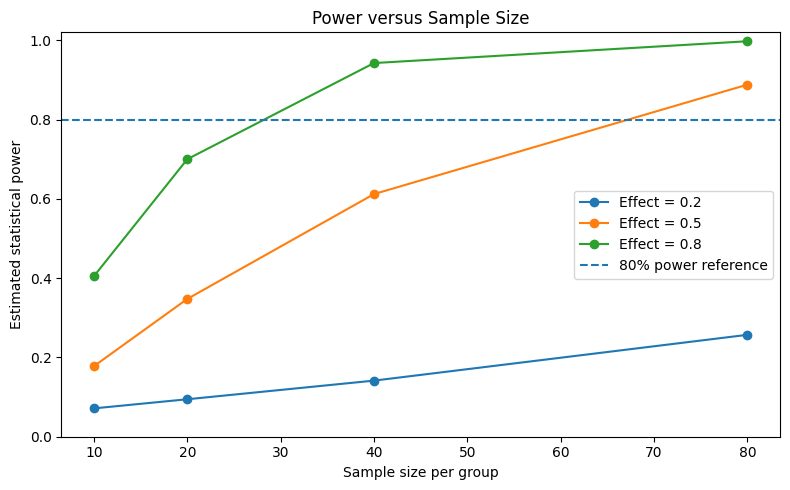

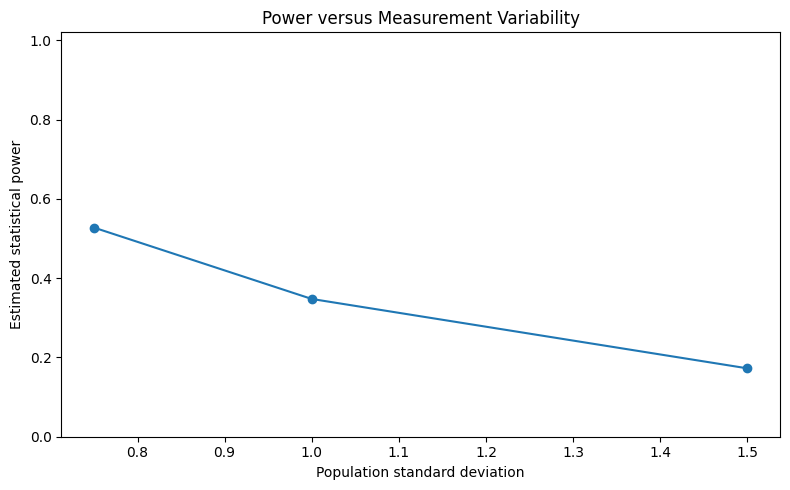

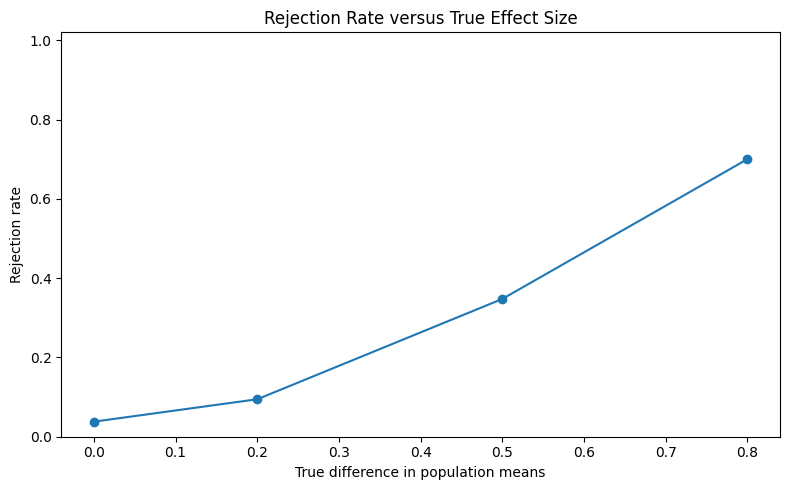

In [17]:
# Figure 1: Power versus sample size, at population SD = 1
plt.figure(figsize=(8, 5))

for effect in [0.2, 0.5, 0.8]:
    subset = power_df[
        (power_df["population_sd"] == 1.0)
        & (power_df["true_effect"] == effect)
    ].sort_values("sample_size_per_group")

    plt.plot(
        subset["sample_size_per_group"],
        subset["rejection_rate"],
        marker="o",
        label=f"Effect = {effect}"
    )

plt.axhline(0.80, linestyle="--", label="80% power reference")
plt.xlabel("Sample size per group")
plt.ylabel("Estimated statistical power")
plt.title("Power versus Sample Size")
plt.ylim(0, 1.02)
plt.legend()
plt.tight_layout()
plt.show()


# Figure 2: Power versus noise, at n = 20 and effect = 0.5
plt.figure(figsize=(8, 5))

subset = power_df[
    (power_df["sample_size_per_group"] == 20)
    & (power_df["true_effect"] == 0.5)
].sort_values("population_sd")

plt.plot(
    subset["population_sd"],
    subset["rejection_rate"],
    marker="o"
)

plt.xlabel("Population standard deviation")
plt.ylabel("Estimated statistical power")
plt.title("Power versus Measurement Variability")
plt.ylim(0, 1.02)
plt.tight_layout()
plt.show()


# Figure 3: Power versus true effect, at n = 20 and SD = 1
plt.figure(figsize=(8, 5))

subset = power_df[
    (power_df["sample_size_per_group"] == 20)
    & (power_df["population_sd"] == 1.0)
].sort_values("true_effect")

plt.plot(
    subset["true_effect"],
    subset["rejection_rate"],
    marker="o"
)

plt.xlabel("True difference in population means")
plt.ylabel("Rejection rate")
plt.title("Rejection Rate versus True Effect Size")
plt.ylim(0, 1.02)
plt.tight_layout()
plt.show()

In [18]:
# Export the complete simulation table
power_df.to_csv(
    "DS-A2_power_simulation_results.csv",
    index=False
)

print("Saved power simulation results.")

Saved power simulation results.


## 8. Assumption-violating counterexample

The pooled-variance Student's t-test assumes that the two populations have equal variances. Welch's t-test does not require this assumption.

To investigate the consequences of violating the equal-variance assumption, we will simulate two independent groups with equal population means but unequal sample sizes and unequal population variances. We will apply both tests repeatedly and compare their Type I error rates with the nominal significance level of 0.05.

This counterexample examines a particular combination of unequal sample sizes and variances. The results will be interpreted in the context of the simulated model rather than as a claim that the pooled-variance test always fails.

Counterexample settings
Control sample size: 10
Treatment sample size: 40
Control population SD: 1.0
Treatment population SD: 2.0
True population mean difference: 0.0

Nominal significance level: 0.05
Welch Type I error rate: 0.0478
Pooled t-test Type I error rate: 0.0049
Welch Monte Carlo SE: 0.0021
Pooled-test Monte Carlo SE: 0.0007


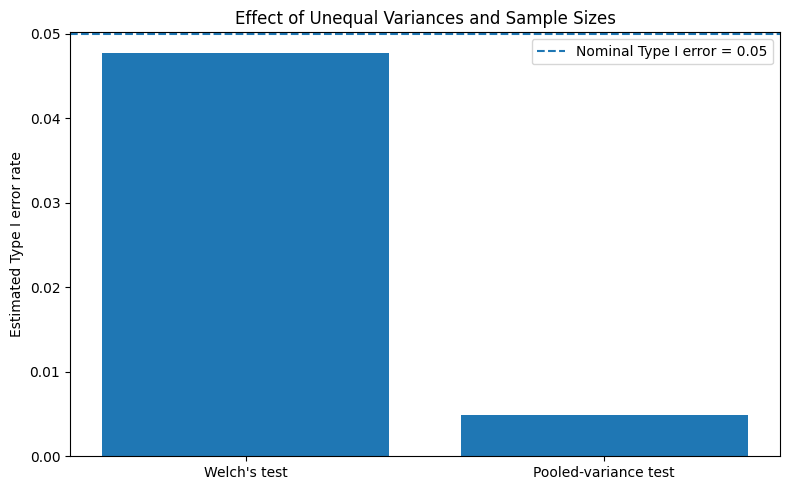

In [19]:
# Step 9: Counterexample with unequal variances and sample sizes

ALPHA = 0.05
N_COUNTEREXAMPLE = 10000

# Equal population means, but unequal variances and sample sizes
N_SMALL = 10
N_LARGE = 40

MEAN_CONTROL = 0.0
MEAN_TREATMENT = 0.0

SD_CONTROL = 1.0
SD_TREATMENT = 2.0

counter_rng = np.random.default_rng(SEED + 4)

# Generate repeated experiments
control = counter_rng.normal(
    loc=MEAN_CONTROL,
    scale=SD_CONTROL,
    size=(N_COUNTEREXAMPLE, N_SMALL)
)

treatment = counter_rng.normal(
    loc=MEAN_TREATMENT,
    scale=SD_TREATMENT,
    size=(N_COUNTEREXAMPLE, N_LARGE)
)

# Sample statistics
mean_c = control.mean(axis=1)
mean_t = treatment.mean(axis=1)

var_c = control.var(axis=1, ddof=1)
var_t = treatment.var(axis=1, ddof=1)

difference = mean_t - mean_c

# Welch's test
welch_se_sq = var_c / N_SMALL + var_t / N_LARGE
welch_se = np.sqrt(welch_se_sq)

welch_df = (
    welch_se_sq ** 2
    / (
        (var_c / N_SMALL) ** 2 / (N_SMALL - 1)
        + (var_t / N_LARGE) ** 2 / (N_LARGE - 1)
    )
)

welch_t = difference / welch_se
welch_p = 2 * stats.t.sf(np.abs(welch_t), df=welch_df)

# Pooled-variance Student's t-test
pooled_var = (
    (N_SMALL - 1) * var_c
    + (N_LARGE - 1) * var_t
) / (N_SMALL + N_LARGE - 2)

pooled_se = np.sqrt(
    pooled_var * (1 / N_SMALL + 1 / N_LARGE)
)

pooled_t = difference / pooled_se
pooled_df = N_SMALL + N_LARGE - 2

pooled_p = 2 * stats.t.sf(
    np.abs(pooled_t),
    df=pooled_df
)

# Type I error rates: both population means are equal
welch_type1 = np.mean(welch_p < ALPHA)
pooled_type1 = np.mean(pooled_p < ALPHA)

print("Counterexample settings")
print("Control sample size:", N_SMALL)
print("Treatment sample size:", N_LARGE)
print("Control population SD:", SD_CONTROL)
print("Treatment population SD:", SD_TREATMENT)
print("True population mean difference:",
      MEAN_TREATMENT - MEAN_CONTROL)

print("\nNominal significance level:", ALPHA)
print("Welch Type I error rate:", round(welch_type1, 4))
print("Pooled t-test Type I error rate:", round(pooled_type1, 4))

# Monte Carlo standard errors
welch_mc_se = np.sqrt(
    welch_type1 * (1 - welch_type1) / N_COUNTEREXAMPLE
)

pooled_mc_se = np.sqrt(
    pooled_type1 * (1 - pooled_type1) / N_COUNTEREXAMPLE
)

print("Welch Monte Carlo SE:", round(welch_mc_se, 4))
print("Pooled-test Monte Carlo SE:", round(pooled_mc_se, 4))

# Visual comparison
plt.figure(figsize=(8, 5))

plt.bar(
    ["Welch's test", "Pooled-variance test"],
    [welch_type1, pooled_type1]
)

plt.axhline(
    ALPHA,
    linestyle="--",
    label="Nominal Type I error = 0.05"
)

plt.ylabel("Estimated Type I error rate")
plt.title("Effect of Unequal Variances and Sample Sizes")
plt.legend()
plt.tight_layout()
plt.show()

### Counterexample results and interpretation

The simulation compared Welch's two-sample t-test with the pooled-variance Student's t-test under the null hypothesis of equal population means. The groups had unequal sample sizes (10 and 40) and unequal population standard deviations (1 and 2).

The estimated Type I error rate was approximately 0.047 for Welch's test and 0.005 for the pooled-variance test. Welch's test therefore maintained a rejection rate close to the nominal 0.05 level, whereas the pooled-variance test was substantially more conservative in this configuration.

This result illustrates that combining unequal sample sizes with unequal variances can affect statistical inference. The pooled-variance test did not produce an inflated Type I error rate in this example; instead, it rejected the true null hypothesis much less frequently than expected. This finding supports using a method appropriate to the variance assumptions and study design. It does not imply that the pooled-variance test always behaves this way.

In [20]:
# Step 10.2: Save counterexample summary results

counterexample_summary = pd.DataFrame({
    "method": [
        "Welch's test",
        "Pooled-variance test"
    ],
    "type1_error_rate": [
        welch_type1,
        pooled_type1
    ],
    "monte_carlo_se": [
        welch_mc_se,
        pooled_mc_se
    ],
    "nominal_alpha": [
        ALPHA,
        ALPHA
    ],
    "repetitions": [
        N_COUNTEREXAMPLE,
        N_COUNTEREXAMPLE
    ]
})

# Display the results
display(counterexample_summary.round(4))

# Save as CSV
counterexample_summary.to_csv(
    "DS-A2_counterexample_results.csv",
    index=False
)

print("Counterexample results saved successfully.")

,method,type1_error_rate,monte_carlo_se,nominal_alpha,repetitions
0,Welch's test,0.0478,0.0021,0.05,10000
1,Pooled-variance test,0.0049,0.0007,0.05,10000


Counterexample results saved successfully.


In [21]:
# Verify counterexample results and column order

print("Column names:")
print(counterexample_summary.columns.tolist())

print("\nCounterexample results:")
print(counterexample_summary.to_string(index=False))

assert len(counterexample_summary) == 2
assert counterexample_summary["method"].tolist() == [
    "Welch's test",
    "Pooled-variance test"
]

print("\nVerification passed.")

Column names:
['method', 'type1_error_rate', 'monte_carlo_se', 'nominal_alpha', 'repetitions']

Counterexample results:
              method  type1_error_rate  monte_carlo_se  nominal_alpha  repetitions
        Welch's test            0.0478        0.002133           0.05        10000
Pooled-variance test            0.0049        0.000698           0.05        10000

Verification passed.


In [22]:
# Save the power-analysis summary again

print("Power results:", power_df.shape)
print("Counterexample results:", counterexample_summary.shape)
print("Both result tables are saved.")

Power results: (48, 5)
Counterexample results: (2, 5)
Both result tables are saved.


In [23]:
# Extract the key power-analysis comparisons

print("1. Power versus sample size (SD = 1):")
print(
    power_df[
        (power_df["population_sd"] == 1.0)
        & (power_df["true_effect"].isin([0.2, 0.5, 0.8]))
    ].sort_values(
        ["true_effect", "sample_size_per_group"]
    ).to_string(index=False)
)

print("\n2. Power versus noise (n = 20, effect = 0.5):")
print(
    power_df[
        (power_df["sample_size_per_group"] == 20)
        & (power_df["true_effect"] == 0.5)
    ].sort_values("population_sd").to_string(index=False)
)

print("\n3. Zero-effect Type I error rates (SD = 1):")
print(
    power_df[
        (power_df["population_sd"] == 1.0)
        & (power_df["true_effect"] == 0.0)
    ].sort_values("sample_size_per_group").to_string(index=False)
)

1. Power versus sample size (SD = 1):
 sample_size_per_group  population_sd  true_effect  rejection_rate  monte_carlo_se
                    10            1.0          0.2          0.0715        0.005761
                    20            1.0          0.2          0.0945        0.006541
                    40            1.0          0.2          0.1415        0.007794
                    80            1.0          0.2          0.2570        0.009771
                    10            1.0          0.5          0.1780        0.008553
                    20            1.0          0.5          0.3475        0.010648
                    40            1.0          0.5          0.6120        0.010896
                    80            1.0          0.5          0.8880        0.007052
                    10            1.0          0.8          0.4050        0.010977
                    20            1.0          0.8          0.7000        0.010247
                    40            1.0          0.

## 9. Interpretation of statistical power

The simulation showed that statistical power increased with sample size and true effect size, while greater population variability reduced power.

When the population standard deviation was 1, the estimated power for a mean difference of 0.5 increased from 0.178 with 10 observations per group to 0.888 with 80 observations per group. For a mean difference of 0.8, power increased from 0.405 to 0.9975 across the same sample-size range. In contrast, with 20 observations per group and a mean difference of 0.5, estimated power decreased from 0.5275 at a population standard deviation of 0.75 to 0.1725 at a standard deviation of 1.5.

Under the zero-effect condition, estimated Type I error rates ranged from 0.038 to 0.0555, reasonably close to the nominal significance level of 0.05 given Monte Carlo uncertainty.

These results demonstrate that statistical power depends on the relationship between effect size, sample size, and variability. They are conditional on the simulated normal distributions and do not estimate power for an actual clinical study of FSIP2-associated male infertility.